# Fintech AML with PySpark

An interactive, presentation-friendly walkthrough of the existing batch pipeline for IBM AMLSim HI-Small transactions. The notebook imports the project's existing modules; it does not copy or redefine sampling, cleaning, feature engineering, splitting, model training, threshold selection, or metric logic.

> **Scope and safety:** AMLSim is simulated data. A model score is not proof of money laundering and must not be used as an automated real-world decision. This notebook is an educational experiment, not a streaming or production AML service.


## 1. Imports, paths, and run controls

Start Jupyter in the project tree (or set `AML_SPARK_PROJECT_DIR`). This cell discovers the repository and adds it to the Python import path before importing project modules. The controls below run training and SQL by default so current-run outputs appear as you execute the later cells.

In [ ]:
import csv
import os
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F

configured_root = os.environ.get("AML_SPARK_PROJECT_DIR")
root_candidates = (
    ([Path(configured_root)] if configured_root else [])
    + [Path.cwd(), *Path.cwd().parents]
)
PROJECT_DIR = next(
    (path.resolve() for path in root_candidates if (path / "main.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find main.py in the current directory or its parents. "
        "Launch Jupyter from the project tree or set AML_SPARK_PROJECT_DIR."
    )

project_path = str(PROJECT_DIR)
if project_path not in sys.path:
    sys.path.insert(0, project_path)

from data_processing import add_features, create_stratified_sample, load_and_clean
from ml_models import train_and_evaluate_models
from spark_sql import run_sql_queries
from visualizations import _curve_points

DATA_PATH = PROJECT_DIR / "data" / "HI-Small_Trans.csv"
SAMPLE_PATH = PROJECT_DIR / "data" / "HI-Small_Trans_sample_500000.csv"
OUTPUT_DIR = PROJECT_DIR / "artifacts" / "hi-small-500k"
SAMPLE_SIZE = 500_000
SAMPLE_SEED = 42

# Training and SQL run so their fresh outputs appear in notebook cells.
# Sampling stays off to reuse the already-generated sample.
RUN_SAMPLING = False
RUN_MODEL_TRAINING = True
RUN_SQL_QUERIES = True

print(f"Project root: {PROJECT_DIR}")
print(f"Python executable: {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")
print(f"Source CSV available: {DATA_PATH.is_file()}")
print(f"Sample available: {SAMPLE_PATH.is_file()}")
print("Run controls:", {
    "RUN_SAMPLING": RUN_SAMPLING,
    "RUN_MODEL_TRAINING": RUN_MODEL_TRAINING,
    "RUN_SQL_QUERIES": RUN_SQL_QUERIES,
})


Project root: D:\Projects\Fintech-secure-aml-spark
Python executable: c:\Users\dell\AppData\Local\Programs\Python\Python310\python.exe
Python version: 3.10.0
Source CSV available: True
Sample available: True
Run controls: {'RUN_SAMPLING': False, 'RUN_MODEL_TRAINING': True, 'RUN_SQL_QUERIES': True}


## 2. Start one local Spark session

These settings match `main.py`: two local worker threads, eight SQL shuffle partitions, and two default parallel tasks. Keep this session alive through the notebook; use the final cleanup cell when finished.

In [17]:
spark = (
    SparkSession.builder.appName("Simple IBM AML Analysis")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.default.parallelism", "2")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print(f"Spark version: {spark.version}")
print(f"Spark master: {spark.sparkContext.master}")

Spark version: 3.5.9
Spark master: local[2]


## 3. Inspect the input header and choose the sample

The source CSV has duplicate `Account` header names. The existing data-preparation module resolves these by position after validating the header names. This cell reads only the CSV header locally; it does not load the full source file into Pandas. By default, the previously generated sample is reused. Set `RUN_SAMPLING = True` above to regenerate it from the original source.

In [18]:
header_path = DATA_PATH if DATA_PATH.is_file() else SAMPLE_PATH
if not header_path.is_file():
    raise FileNotFoundError(
        "Neither the source CSV nor the prepared sample was found. Place "
        "HI-Small_Trans.csv in data\\, or provide the existing sample."
    )

with header_path.open(encoding="utf-8-sig", newline="") as csv_file:
    source_header = next(csv.reader(csv_file), None)
if not source_header:
    raise ValueError(f"No CSV header found in {header_path}")

print(f"Header read from: {header_path.name}")
print(f"Column count: {len(source_header)}")
display(pd.DataFrame({"column_position": range(len(source_header)), "column_name": source_header}))

Header read from: HI-Small_Trans.csv
Column count: 11


,column_position,column_name
0,0,Timestamp
1,1,From Bank
2,2,Account
3,3,To Bank
4,4,Account
5,5,Amount Received
6,6,Receiving Currency
7,7,Amount Paid
8,8,Payment Currency
9,9,Payment Format


In [19]:
source_stats = {}
if RUN_SAMPLING:
    if not DATA_PATH.is_file():
        raise FileNotFoundError(f"Cannot sample because the original CSV is missing: {DATA_PATH}")
    selected_sample = Path(
        create_stratified_sample(
            spark,
            str(DATA_PATH),
            str(SAMPLE_PATH),
            SAMPLE_SIZE,
            SAMPLE_SEED,
            source_stats,
        )
    )
    print(f"Created reproducible sample: {selected_sample}")
else:
    selected_sample = SAMPLE_PATH
    if not selected_sample.is_file():
        raise FileNotFoundError(
            f"Prepared sample not found: {selected_sample}. Add the sample file "
            "or set RUN_SAMPLING = True and provide the original source CSV."
        )
    print(f"Reusing existing sample: {selected_sample}")
    print("Sampling was not rerun; source class counts are not recalculated in this mode.")

Reusing existing sample: D:\Projects\Fintech-secure-aml-spark\data\HI-Small_Trans_sample_500000.csv
Sampling was not rerun; source class counts are not recalculated in this mode.


## 4. Load, clean, and inspect prepared transactions

`load_and_clean` parses supported timestamps and numeric amounts, constructs bank-qualified sender/receiver IDs, creates a deterministic transaction ID, and removes invalid rows. `add_features` adds the existing amount-range indicator. The prepared DataFrame is cached on disk as in the script pipeline, counted once for the expected sample-size check, and then reused by later cells. Only a few rows and small aggregate summaries are brought to the notebook driver.

In [ ]:
if "transactions" in globals() and transactions is not None:
    transactions.unpersist()    
transactions = add_features(load_and_clean(spark, str(selected_sample))).persist(
    StorageLevel.DISK_ONLY
)
transaction_count = transactions.count()
if transaction_count != SAMPLE_SIZE:
    raise ValueError(
        f"Expected {SAMPLE_SIZE:,} valid prepared rows, got {transaction_count:,}."
    )
print(f"Prepared rows: {transaction_count:,}")
print(f"Prepared columns: {len(transactions.columns)}")
transactions.printSchema()
display(transactions.limit(8).toPandas())

Prepared rows: 500,000
Prepared columns: 8
root
 |-- transaction_id: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- sender_account: string (nullable = true)
 |-- receiver_account: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- is_laundering: integer (nullable = true)
 |-- is_near_threshold: integer (nullable = true)



,transaction_id,timestamp,sender_account,receiver_account,amount,payment_type,is_laundering,is_near_threshold
0,105dcf63600629bd34f815df0349202a8231cc92d6d8d1...,2022-09-10 01:51:00,0045304:8115860C0,0046906:811588F30,8885.03,ACH,0,0
1,c9190d0bca26130f5fe913ee44d84bdf59a75e88e9af5f...,2022-09-02 20:08:00,01467:800268E80,001068:800F74A20,183.56,Credit Card,0,0
2,a092e547d7f33382454227b623543cef263b23d58982ae...,2022-09-05 22:57:00,003229:8066F3960,001412:806C10A70,3120.89,Credit Card,0,0
3,8d93756e2048f6153d7ccef5bcc9f0dfda5ba94608d24f...,2022-09-01 19:08:00,00701:8004E4020,00701:8004E4020,30046.41,Reinvestment,0,0
4,4147b8620ba26a48299b03ef20f68c12a38dbcc57bfcd1...,2022-09-01 23:51:00,029467:80390ABF0,0212156:80C40AFE0,113557.21,Credit Card,0,0
5,a3639725d52a3fc5708ac7f1823bb8de838e2e5b533e29...,2022-09-08 18:10:00,015:8039DA9B0,015:803F26EA0,684213.18,ACH,0,0
6,4a51a87a7c808a60c3cab92031ef61a1dcb48b63cd548f...,2022-09-06 00:23:00,016224:808D6E8C0,005140:80D1FCB30,11.08,Credit Card,0,0
7,133ad7709850edf24860bd7a8944ba904a1c8a96f206b6...,2022-09-01 07:30:00,070:100428978,0118:80DC09890,30.73,Cheque,0,0


In [21]:
null_summary = transactions.agg(
    F.count("*").alias("prepared_rows"),
    *[
        F.sum(F.when(F.col(column).isNull(), 1).otherwise(0)).alias(f"{column}_nulls")
        for column in transactions.columns
    ],
).first().asDict()
display(pd.DataFrame([null_summary]).T.rename(columns={0: "count"}))

,count
prepared_rows,500000
transaction_id_nulls,0
timestamp_nulls,0
sender_account_nulls,0
receiver_account_nulls,0
amount_nulls,0
payment_type_nulls,0
is_laundering_nulls,0
is_near_threshold_nulls,0


## 5. Target distribution and class imbalance

The target is `is_laundering` (`1` = AML-positive, `0` = AML-negative). Counts and proportions are aggregated in Spark; only the two-row summary is converted to Pandas. Because positives are rare, accuracy alone is not a sufficient model-quality measure.

,class_name,count,percentage
0,AML-negative,499490,99.898
1,AML-positive,510,0.102


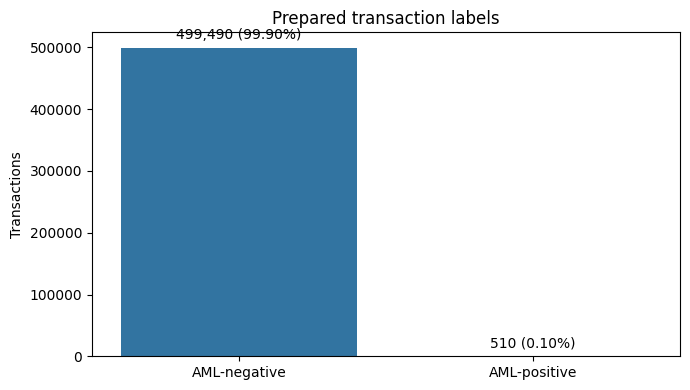

In [22]:
class_distribution = (
    transactions.groupBy("is_laundering")
    .count()
    .orderBy("is_laundering")
    .toPandas()
)
class_distribution["class_name"] = class_distribution["is_laundering"].map(
    {0: "AML-negative", 1: "AML-positive"}
)
class_distribution["percentage"] = (
    class_distribution["count"] / class_distribution["count"].sum() * 100
)
display(class_distribution[["class_name", "count", "percentage"]])

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=class_distribution, x="class_name", y="count", hue="class_name", legend=False, ax=ax)
for bar, row in zip(ax.patches, class_distribution.itertuples()):
    ax.annotate(
        f"{row.count:,} ({row.percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
    )
ax.set(title="Prepared transaction labels", xlabel="", ylabel="Transactions")
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. Existing feature engineering

The source pipeline adds one engineered feature: `is_near_threshold = 1` for amounts in `[9,000, 10,000)`. The models also use `amount` and a `payment_type_index` fitted on training rows. No new feature transformations are introduced here. The following small aggregate is descriptive only.

In [23]:
feature_summary = (
    transactions.groupBy("is_near_threshold")
    .agg(
        F.count("*").alias("transaction_count"),
        F.min("amount").alias("minimum_amount"),
        F.avg("amount").alias("average_amount"),
        F.max("amount").alias("maximum_amount"),
    )
    .orderBy("is_near_threshold")
    .toPandas()
)
display(feature_summary)

,is_near_threshold,transaction_count,minimum_amount,average_amount,maximum_amount
0,0,495007,0.000001,3.587389e+06,8.485314e+10
1,1,4993,9000.060000,9.492316e+03,9.999920e+03


## 7. Chronological split and model training

The existing model code uses timestamp quantiles for approximately 60% training, 20% validation, and 20% future test data. Duplicate timestamps may make exact row percentages differ. The split is chronological rather than randomly stratified, so temporal changes in positive prevalence remain visible. `ml_models.py` fits the payment-format indexer and class weights on training data only, then selects each model's F1-maximizing probability threshold on validation data.

The existing classifiers and hyperparameters are:

- **Decision tree:** maximum depth 4, seed 42.
- **Random forest:** 8 trees, maximum depth 4, square-root feature subset, seed 42.
- **Gradient-boosted trees:** 5 iterations, maximum depth 3, step size 0.1, seed 42.

The helper trains these three models sequentially, evaluates each against the same future test period, and records actual split counts. The operation is deliberately opt-in; it is not run when opening or executing the notebook with its default configuration.

In [24]:
model_metrics = None
if RUN_MODEL_TRAINING:
    # The existing helper writes its metrics CSV; keep that side effect temporary
    # so this notebook displays results without adding files to project artifacts.
    with tempfile.TemporaryDirectory(prefix="aml-spark-notebook-") as temporary_output:
        model_metrics = train_and_evaluate_models(
            transactions,
            temporary_output,
            source_stats=source_stats or None,
            sample_size=SAMPLE_SIZE,
            sample_seed=SAMPLE_SEED,
        )
    print("Training complete. Temporary metrics files were removed.")

    preview_rows = 20
    for result in model_metrics:
        probabilities = np.asarray(result["_test_probabilities"], dtype=float)
        actual_labels = np.asarray(result["_test_labels"], dtype=int)
        predicted_labels = (probabilities >= float(result["threshold"])).astype(int)
        prediction_preview = pd.DataFrame({
            "test_row_order": np.arange(1, min(preview_rows, len(actual_labels)) + 1),
            "actual_label": actual_labels[:preview_rows],
            "predicted_label": predicted_labels[:preview_rows],
            "positive_probability": probabilities[:preview_rows],
        })
        print(f"{result['model']} ? first {len(prediction_preview)} test predictions")
        display(prediction_preview)
else:
    print("Model training skipped. Set RUN_MODEL_TRAINING = True to train all three models.")



DATA USAGE REPORT (before model training)
Source row count and source class counts: unavailable.
Sample row count: 500,000; requested size: 500,000; seed: 42.
Sample AML-positive: 510 (0.1020%); AML-negative: 499,490 (99.8980%).
Train: 299,730 rows; AML-positive=212 (0.0707%); AML-negative=299,518.
Validation: 99,881 rows; AML-positive=103 (0.1031%); AML-negative=99,778.
Test: 100,389 rows; AML-positive=195 (0.1942%); AML-negative=100,194.
Model features (3): amount, is_near_threshold, payment_type_index
DecisionTreeClassifier: 100,389 test rows to evaluate; training time pending.
RandomForestClassifier: 100,389 test rows to evaluate; training time pending.
GBTClassifier: 100,389 test rows to evaluate; training time pending.
Total runtime: in progress.
Split policy: chronological by timestamp (60% train, 20% validation, 20% test quantiles). Positive-rate differences are measured temporal distribution shift, not stratified away; timestamps and labels are excluded from model features.
L

,test_row_order,actual_label,predicted_label,positive_probability
0,1,0,1,0.902052
1,2,0,1,0.902052
2,3,0,0,0.174970
3,4,0,0,0.174970
4,5,0,1,0.902052
5,6,0,0,0.174970
6,7,0,0,0.174970
7,8,0,0,0.174970
8,9,0,0,0.174970
9,10,0,0,0.174970


RandomForestClassifier ? first 20 test predictions


,test_row_order,actual_label,predicted_label,positive_probability
0,1,0,1,0.907338
1,2,0,0,0.900636
2,3,0,0,0.193389
3,4,0,0,0.196235
4,5,0,1,0.907338
5,6,0,0,0.196235
6,7,0,0,0.195966
7,8,0,0,0.192381
8,9,0,0,0.192381
9,10,0,0,0.203092


GBTClassifier ? first 20 test predictions


,test_row_order,actual_label,predicted_label,positive_probability
0,1,0,1,0.875354
1,2,0,0,0.859606
2,3,0,0,0.229103
3,4,0,0,0.208393
4,5,0,1,0.875354
5,6,0,0,0.208393
6,7,0,0,0.208393
7,8,0,0,0.208393
8,9,0,0,0.208393
9,10,0,0,0.264027


## 8. Spark SQL analysis (optional)

The project defines seven SQL queries for transaction filters, sender summaries, payment formats, aggregate statistics, joins, wildcard matching, and AML rates by payment format. They run only when `RUN_SQL_QUERIES = True`. Query results are bounded or aggregate summaries; only a small preview is converted to Pandas, while complete result CSVs are saved to the existing SQL output directory.

In [25]:
if RUN_SQL_QUERIES:
    sql_results = run_sql_queries(spark, transactions)
    for query_name, result in sql_results.items():
        # The existing queries return at most 20 rows or small aggregate tables.
        result_table = result.toPandas()
        print(f"{query_name}: {len(result_table):,} rows")
        display(result_table)
else:
    print("SQL execution skipped. Set RUN_SQL_QUERIES = True to run the seven queries.")


high_value_transactions: 20 rows


,transaction_id,sender_account,receiver_account,amount,payment_type
0,e0565449185c62fec25a8a55dbc168a59ced725410b45a...,004:806B9AF90,0116781:806B9B6A0,8.485314e+10,ACH
1,2762ab5f796daf6a9637530dd4b90dc775e44e300ce097...,015964:8026E7B20,0114590:805FBE280,6.943162e+10,Cheque
2,06ebe610f53707475e67659429d56a7d9e323ae80b1239...,014433:8023B9740,021:80368E630,5.867878e+10,Cash
3,117dea01ede0fcea4b9c46cfb4530e977d0a1b15847513...,0112497:804BB7A20,0014381:80551B160,4.588228e+10,Cheque
4,e47956ae7a3919c3c5ad8500b3da1af98baca506fca672...,029467:8039E0E70,009665:803A9D5B0,4.236227e+10,Cheque
5,9d19715c1a3a99b12b0a3d251b040002bef086371b76c7...,0133686:80C776BF0,0133452:80C9F7FC0,2.862364e+10,Cheque
6,b07882e01f551791debb23beb7576346eff2b194bca509...,0010060:804033940,0011128:80C4C9CD0,2.372960e+10,Cash
7,bd65b78117d882530f8ba954f08490d63720b40876edda...,0010060:804033940,0011128:80C4C9CD0,2.372960e+10,Cash
8,8562c07ce120fd7b17c2a039d2bfc1512dece669fa9c05...,0010057:803B18040,009665:803EFB7B0,2.129130e+10,ACH
9,d9c9c1348a42229b0698b4ef1cedee88adfa7f9e4fc12d...,0017554:806BFCF10,0219562:8073B0B30,1.923524e+10,Wire


active_senders: 20 rows


,sender_account,transaction_count,total_sent
0,070:100428660,16544,3.865869e+09
1,070:1004286A8,9962,3.236513e+09
2,070:100428978,2033,7.579458e+08
3,070:1004286F0,1814,3.424020e+09
4,070:100428780,1714,1.589368e+10
5,070:1004289C0,1646,2.309197e+09
6,070:100428810,1593,4.033332e+08
7,070:1004287C8,1430,8.639319e+09
8,070:100428738,1379,1.524819e+10
9,070:100428A51,1296,2.899480e+04


payment_types: 7 rows


...

,transaction_id,sender_account,amount,transaction_count,average_amount
0,58528390079edf2a0eefe445324b37ddb965ee8d159db4...,070:100428660,2.231374e+08,16544,233671.989953
1,65fa475bc7d12513c8b94f25dd7f32ff437bb201a2c27d...,070:100428660,1.804889e+08,16544,233671.989953
2,5213dda93f65639728dedddd90d2d18df6208fd8ae62b1...,070:100428660,1.603318e+08,16544,233671.989953
3,d7f29189284b5b0896e66313cd5d053a00bb31a1c02f22...,070:100428660,1.529994e+08,16544,233671.989953
4,cc54ccf431e4b027b4e0cf9e442455556c89b403cdb60f...,070:100428660,1.472978e+08,16544,233671.989953
5,49c77e499c337549470c69e98b90428e1d80c7c29647e0...,070:100428660,1.374802e+08,16544,233671.989953
6,f58787caf71deb6c55552c2bf121aba73ecd9f6a379a0f...,070:100428660,9.138834e+07,16544,233671.989953
7,a9537978a6ce34159e469a43bddc9018ed20587de8c426...,070:100428660,7.599656e+07,16544,233671.989953
8,a6bbd0cf7a09b8b15e2d472893eb207772f35460222aad...,070:100428660,7.487179e+07,16544,233671.989953
9,a6ba92855f68eb9cf60d24e3022a5553337e0e8310c058...,070:100428660,6.740594e+07,16544,233671.989953


wildcard_payment_search: 20 rows


,transaction_id,payment_type,amount
0,2762ab5f796daf6a9637530dd4b90dc775e44e300ce097...,Cheque,6.943162e+10
1,117dea01ede0fcea4b9c46cfb4530e977d0a1b15847513...,Cheque,4.588228e+10
2,e47956ae7a3919c3c5ad8500b3da1af98baca506fca672...,Cheque,4.236227e+10
3,9d19715c1a3a99b12b0a3d251b040002bef086371b76c7...,Cheque,2.862364e+10
4,d9c9c1348a42229b0698b4ef1cedee88adfa7f9e4fc12d...,Wire,1.923524e+10
5,953e42e08ce254cef3c023ba898695805968ffa0169982...,Cheque,1.879759e+10
6,cea9a862f1a1a590fbfc88692b83baa630e60550db248d...,Cheque,1.811758e+10
7,af36815beec6381f173b5aefe96cfce45fbecc37b88ee2...,Cheque,1.745376e+10
8,8bf219782f45af7b3ea3f1ac2057e661dffddb5183f001...,Cheque,1.637701e+10
9,802fca9a6bbaa842050bcefb579dae7170af69caa090e1...,Cheque,1.603091e+10


aml_rate_by_payment_type: 7 rows


,payment_type,transaction_count,aml_positive,aml_rate
0,ACH,59038,439,0.007436
1,Cash,48278,14,0.000290
2,Bitcoin,14370,4,0.000278
3,Cheque,183571,32,0.000174
4,Credit Card,130415,21,0.000161
5,Wire,17004,0,0.000000
6,Reinvestment,47324,0,0.000000


## 9. Compare model metrics

If training ran in this kernel, the table is built from those returned model outputs. Otherwise it reads the existing `model_metrics.csv` artifact and labels it as a saved run; the notebook does not invent metrics or imply that training just occurred. Accuracy is shown alongside precision, recall, F1, PR-AUC, and ROC-AUC because the target is highly imbalanced.

In [26]:
if model_metrics is None:
    raise RuntimeError(
        "Fresh metrics are not available. Run the model-training cell first; "
        "this notebook intentionally does not load old saved scores."
    )

metric_columns = [
    "model", "accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc",
    "tp", "tn", "fp", "fn", "threshold",
]
metrics_table = pd.DataFrame(
    [{column: result[column] for column in metric_columns} for result in model_metrics]
)
split_stats = model_metrics[0]["_split_stats"]
print("Metrics are from the models trained in this notebook run.")
display(
    metrics_table.style.format({
        "accuracy": "{:.4f}", "precision": "{:.4f}",
        "recall": "{:.4f}", "f1": "{:.4f}",
        "pr_auc": "{:.4f}", "roc_auc": "{:.4f}",
        "threshold": "{:.4f}",
    }).set_caption("Fresh chronological test-set model comparison")
)

split_table = pd.DataFrame([
    {
        "split": split_name.title(),
        **counts,
        "positive_rate": counts["positive"] / counts["rows"],
    }
    for split_name, counts in split_stats.items()
])
display(split_table.style.format({"positive_rate": "{:.4%}"}).set_caption("Actual chronological split sizes"))


Metrics are from the models trained in this notebook run.


,model,accuracy,precision,recall,f1,pr_auc,roc_auc,tp,tn,fp,fn,threshold
0,DecisionTreeClassifier,0.8947,0.0170,0.9385,0.0335,0.0165,0.9129,183,89634,10560,12,0.9021
1,RandomForestClassifier,0.9805,0.0472,0.4718,0.0857,0.0315,0.9428,92,98335,1859,103,0.9073
2,GBTClassifier,0.9639,0.0332,0.6256,0.0631,0.0291,0.9368,122,96642,3552,73,0.8754


,split,rows,positive,negative,positive_rate
0,Train,299730,212,299518,0.0707%
1,Validation,99881,103,99778,0.1031%
2,Test,100389,195,100194,0.1942%


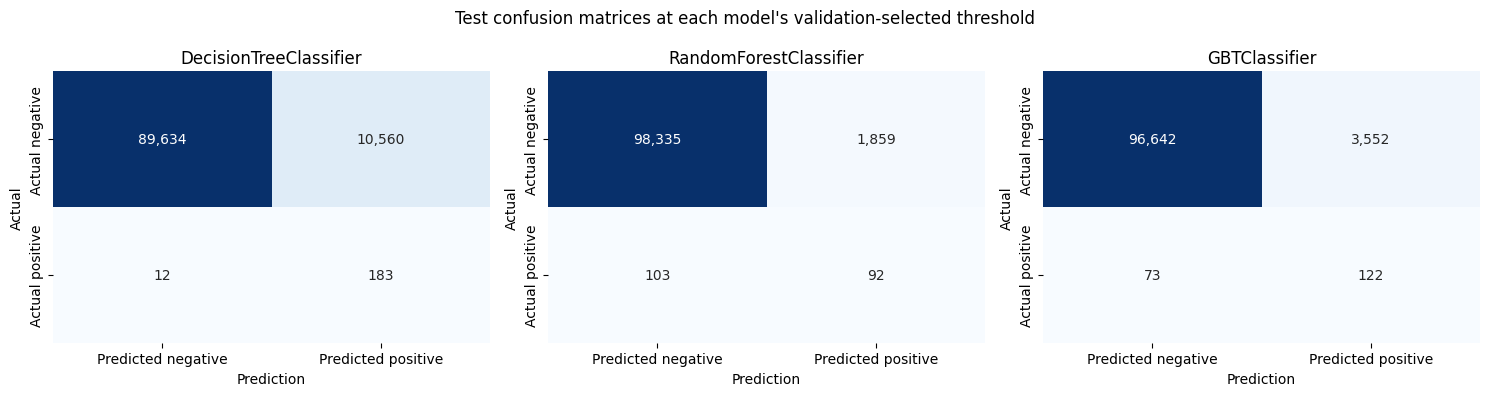

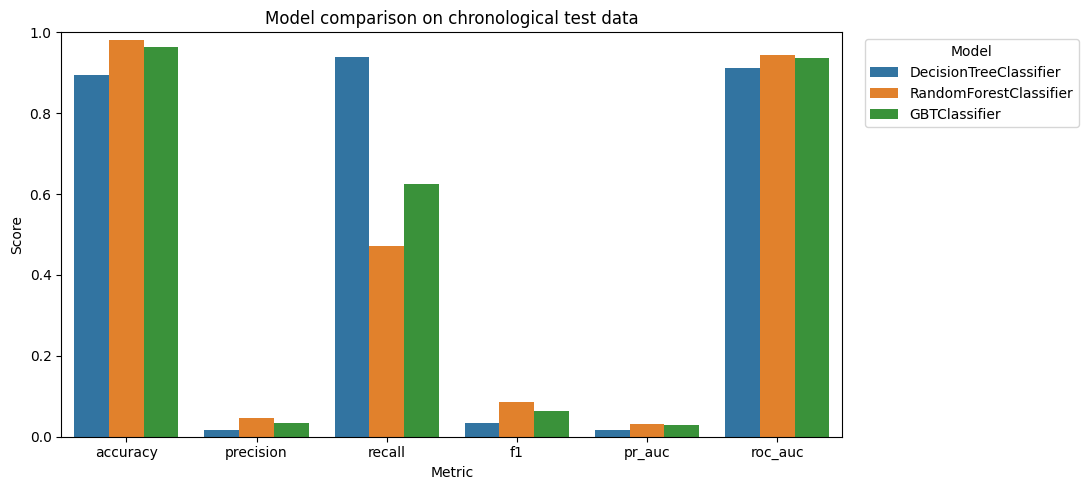

Highest test F1 in the displayed metrics: RandomForestClassifier
Interpret precision/recall together with prevalence and review capacity; accuracy alone is not evidence of useful AML detection.


In [27]:
if metrics_table is not None:
    fig, axes = plt.subplots(1, len(metrics_table), figsize=(5 * len(metrics_table), 4))
    if len(metrics_table) == 1:
        axes = [axes]
    for axis, row in zip(axes, metrics_table.itertuples(index=False)):
        confusion = pd.DataFrame(
            [[row.tn, row.fp], [row.fn, row.tp]],
            index=["Actual negative", "Actual positive"],
            columns=["Predicted negative", "Predicted positive"],
        )
        sns.heatmap(confusion, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axis)
        axis.set_title(row.model)
        axis.set_xlabel("Prediction")
        axis.set_ylabel("Actual")
    fig.suptitle("Test confusion matrices at each model's validation-selected threshold")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    comparison = metrics_table.melt(
        id_vars="model",
        value_vars=["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc"],
        var_name="metric",
        value_name="score",
    )
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.barplot(data=comparison, x="metric", y="score", hue="model", ax=ax)
    ax.set(title="Model comparison on chronological test data", xlabel="Metric", ylabel="Score", ylim=(0, 1))
    ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    best_f1_model = metrics_table.loc[metrics_table["f1"].idxmax(), "model"]
    print(f"Highest test F1 in the displayed metrics: {best_f1_model}")
    print("Interpret precision/recall together with prevalence and review capacity; accuracy alone is not evidence of useful AML detection.")

## 10. Visualize existing or newly generated plots

When training was run in this session, set `REGENERATE_PLOTS = True` and rerun this cell to call the existing plotting module without opening blocking desktop windows. That module uses the current model outputs, including test-score curves. If training was skipped, this cell displays the saved PNGs as **previously generated artifacts** when available; it does not retrain or recalculate their curves.

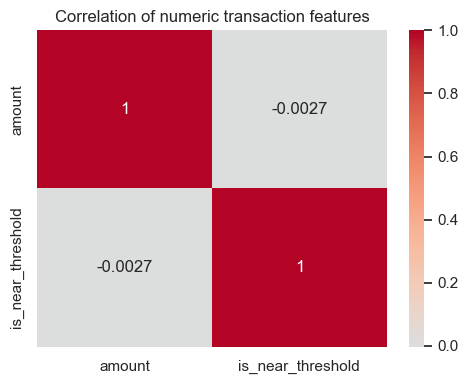

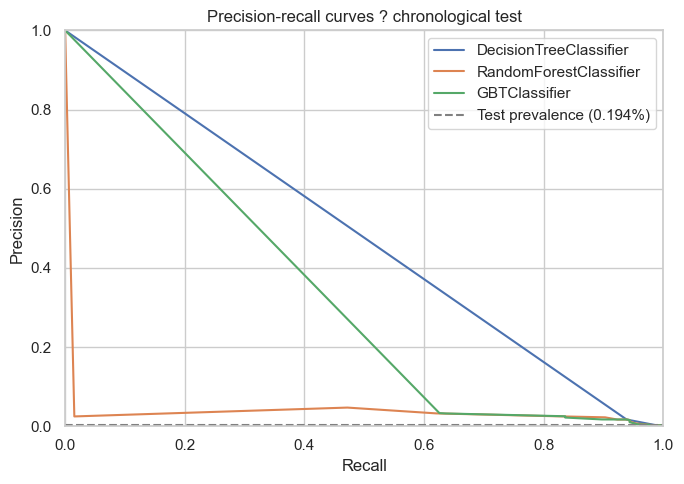

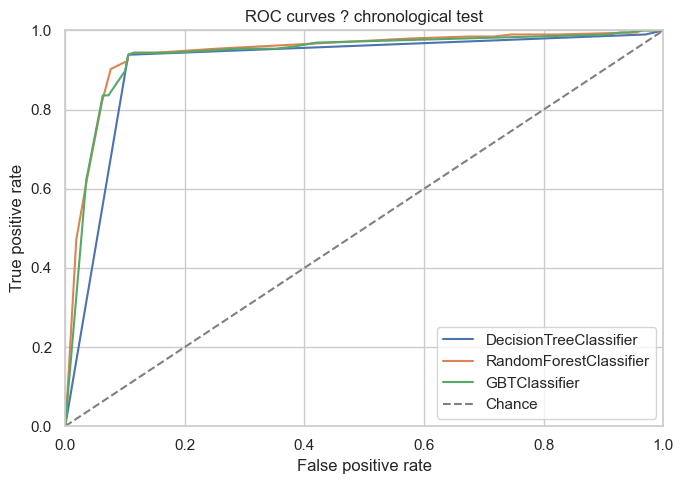

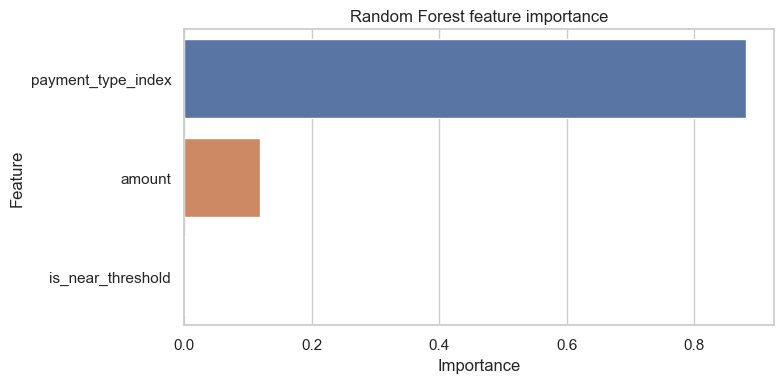

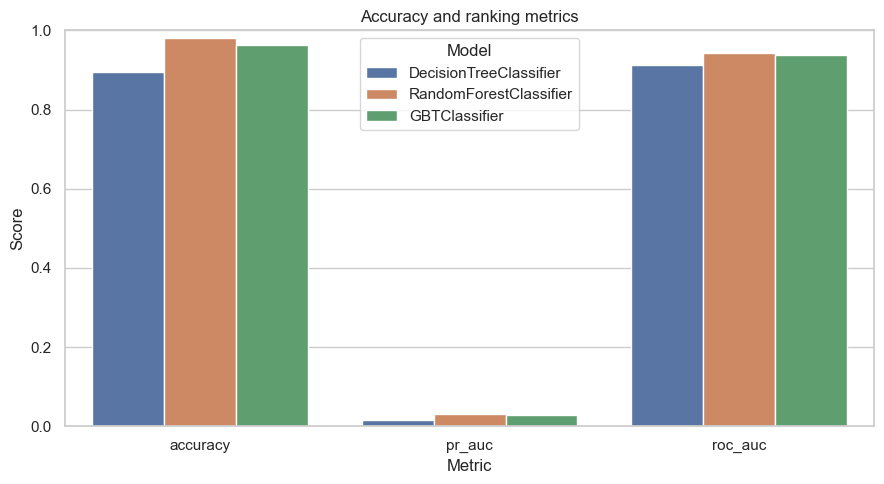

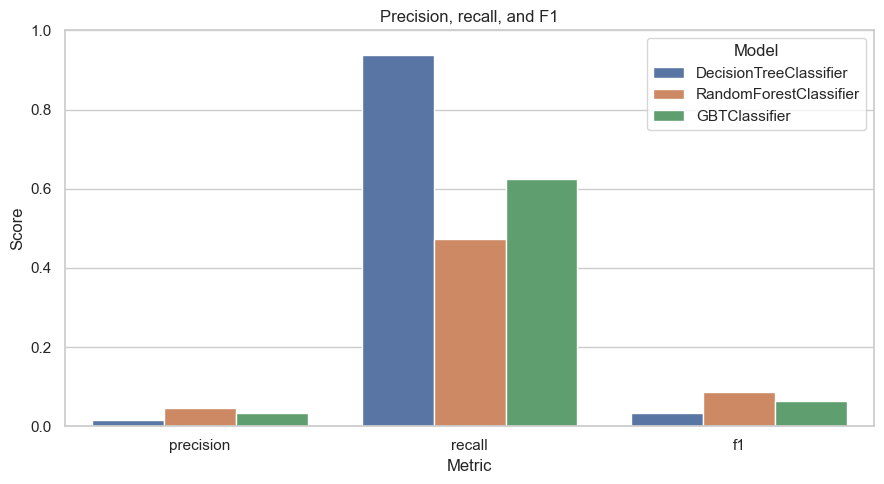

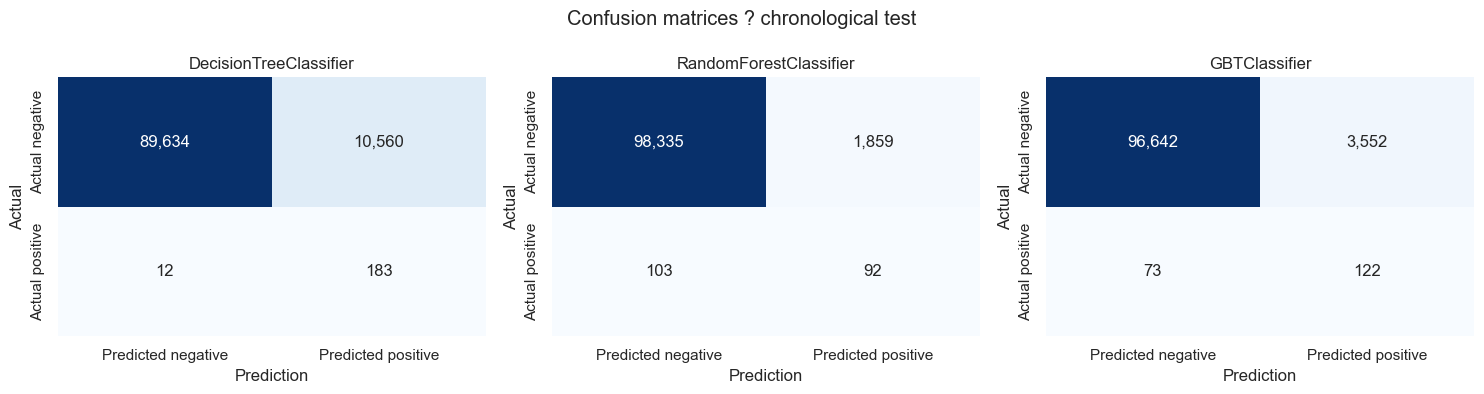

All charts were rendered inline and were not saved to files.


In [28]:
if model_metrics is None:
    raise RuntimeError("Run model training before generating current-run plots.")

sns.set_theme(style="whitegrid")

# 1. Correlation heatmap, matching the project's bounded 20,000-row sample.
correlation_sample = (
    transactions.select("amount", "is_near_threshold")
    .sample(False, 0.1, seed=42)
    .limit(20_000)
    .toPandas()
)
if correlation_sample.empty:
    correlation_sample = transactions.select("amount", "is_near_threshold").limit(20_000).toPandas()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(correlation_sample.corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of numeric transaction features")
fig.tight_layout()
plt.show()
plt.close(fig)

# 2?3. Curves use this run's own chronological test labels and probabilities.
for curve_name in ("precision_recall", "roc"):
    fig, ax = plt.subplots(figsize=(7, 5))
    for result in model_metrics:
        recall, precision, fpr, tpr = _curve_points(
            result["_test_labels"], result["_test_probabilities"]
        )
        if curve_name == "precision_recall":
            ax.plot(recall, precision, label=result["model"])
        else:
            ax.plot(fpr, tpr, label=result["model"])
    if curve_name == "precision_recall":
        prevalence = float(np.mean(model_metrics[0]["_test_labels"]))
        ax.axhline(prevalence, linestyle="--", color="gray", label=f"Test prevalence ({prevalence:.3%})")
        ax.set(title="Precision-recall curves ? chronological test", xlabel="Recall", ylabel="Precision")
    else:
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
        ax.set(title="ROC curves ? chronological test", xlabel="False positive rate", ylabel="True positive rate")
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# 4. Random Forest feature importance from the fitted model result.
forest_result = next(result for result in model_metrics if "_feature_importances" in result)
importance = pd.DataFrame([
    {"feature": feature, "importance": value}
    for feature, value in forest_result["_feature_importances"].items()
]).sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=importance, x="importance", y="feature", hue="feature", legend=False, ax=ax)
ax.set(title="Random Forest feature importance", xlabel="Importance", ylabel="Feature")
fig.tight_layout()
plt.show()
plt.close(fig)

# 5?6. Side-by-side metric comparisons from the current test results.
for columns, title in (
    (["accuracy", "pr_auc", "roc_auc"], "Accuracy and ranking metrics"),
    (["precision", "recall", "f1"], "Precision, recall, and F1"),
):
    chart_data = metrics_table.melt(id_vars="model", value_vars=columns, var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=chart_data, x="metric", y="score", hue="model", ax=ax)
    ax.set(title=title, xlabel="Metric", ylabel="Score", ylim=(0, 1))
    ax.legend(title="Model")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# 7. Confusion matrices at the validation-selected thresholds.
fig, axes = plt.subplots(1, len(model_metrics), figsize=(5 * len(model_metrics), 4))
if len(model_metrics) == 1:
    axes = [axes]
for ax, result in zip(axes, model_metrics):
    matrix = pd.DataFrame(
        [[result["tn"], result["fp"]], [result["fn"], result["tp"]]],
        index=["Actual negative", "Actual positive"],
        columns=["Predicted negative", "Predicted positive"],
    )
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(result["model"])
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices ? chronological test")
fig.tight_layout()
plt.show()
plt.close(fig)
print("All charts were rendered inline and were not saved to files.")


## 11. Conclusions and limitations

- The evaluation is chronological, and each model's threshold is chosen on validation data rather than on the future test period.
- AML positives are rare, so a high accuracy or ROC-AUC can coexist with low precision. Review precision, recall, F1, PR-AUC, and confusion counts together.
- The current models use only amount, the existing amount-range flag, and payment-format index. Account histories, graph relationships, and customer context are not model features.
- AMLSim is simulated data; these results do not establish performance on real banking data.
- This repository implements local batch analysis, not streaming detection, deployment, case management, or an automated compliance decision process.

For an interview, describe this as a reproducible Spark batch-analysis and model-comparison prototype. Be explicit about rare-class trade-offs, chronological evaluation, and the limitations of simulated data.

## 12. Release Spark resources

Run this final cell when finished. If you want to continue exploring, keep Spark alive and run it later. Rerunning data-loading or training cells after stopping Spark requires rerunning the Spark initialization cell first.

In [29]:
if "transactions" in globals() and transactions is not None:
    transactions.unpersist()
if "spark" in globals() and spark is not None:
    spark.stop()
    print("Spark session stopped and prepared transaction cache released.")

Spark session stopped and prepared transaction cache released.
